In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.1.2+cpu


In [3]:
# Step 2 — Generate mobility data

rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

# Binary target: late if wait >= 10 minutes
df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())
print("Shape:", df.shape)
print(df["late"].value_counts())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


Shape: (500, 7)
late
0    290
1    210
Name: count, dtype: int64


In [4]:
# function 1: convert data to Tensor
def to_tensors(X, y):
    X_tensor = torch.tensor(
        np.asarray(X),
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        np.asarray(y).reshape(-1, 1),
        dtype=torch.float32
    )

    return X_tensor, y_tensor

# function 2: model training
def train_torch_model(
    model,
    X_train_tensor,
    y_train_tensor,
    loss_fn,
    epochs=1200,
    lr=0.05
):
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    loss_history = []

    for epoch in range(epochs):

        model.train()

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(X_train_tensor)

        # 3. Calculate loss
        loss = loss_fn(outputs, y_train_tensor)

        # 4. Backpropagation
        loss.backward()

        # 5. Update parameters
        optimizer.step()

        loss_history.append(loss.item())

    model.eval()

    return loss_history

<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Demand')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'Demand vs. Waiting Time')

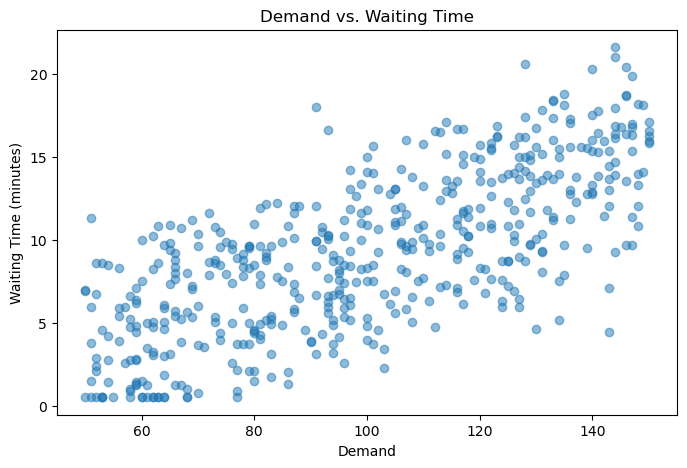

Correlation: 0.7235822950357308


In [5]:
# Task 1 — Explore the relationship

plt.figure(figsize=(8, 5))

plt.scatter(
    df["demand"],
    df["wait_min"],
    alpha=0.5
)

plt.xlabel("Demand")
plt.ylabel("Waiting Time (minutes)")
plt.title("Demand vs. Waiting Time")
plt.show()

print(
    "Correlation:",
    df["demand"].corr(df["wait_min"])
)

In [6]:
# Task 2 — Prepare data and fit Simple Linear Regression

# Step A — Split and standardize

X = df[["demand"]]
y = df["wait_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Standardize X using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_t, y_train_t = to_tensors(
    X_train_scaled, y_train
)

X_test_t, y_test_t = to_tensors(
    X_test_scaled, y_test
)

print("Training X shape:", X_train_t.shape)
print("Training y shape:", y_train_t.shape)

Training X shape: torch.Size([375, 1])
Training y shape: torch.Size([375, 1])


In [7]:
# Step B — Define and train the model

torch.manual_seed(42)

linear_model = nn.Linear(
    in_features=1,
    out_features=1
)

loss_fn = nn.MSELoss()

loss_history = train_torch_model(
    model=linear_model,
    X_train_tensor=X_train_t,
    y_train_tensor=y_train_t,
    loss_fn=loss_fn,
    epochs=1200,
    lr=0.05
)

print("Final training MSE:", loss_history[-1])

Final training MSE: 11.043916702270508


<Figure size 800x400 with 0 Axes>

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'MSE Loss')

Text(0.5, 1.0, 'Linear Regression — Training Loss')

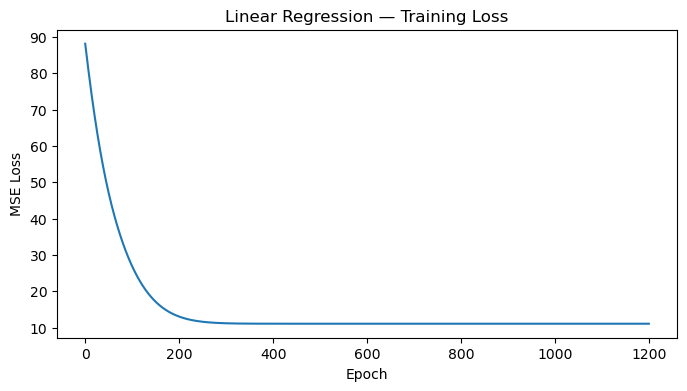

In [8]:
# Step C — Plot the training loss

plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Linear Regression — Training Loss")

plt.show()

In [9]:
# Task 3 — Interpret the coefficients

w_scaled = linear_model.weight.item()
b_scaled = linear_model.bias.item()

# Convert coefficients to original demand units
slope = w_scaled / scaler.scale_[0]

intercept = (
    b_scaled
    - slope * scaler.mean_[0]
)

print("Intercept:", intercept)
print("Slope:", slope)

Intercept: -2.848379600750178
Slope: 0.1209982414123141


<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Demand')

Text(0, 0.5, 'Waiting Time (minutes)')

Text(0.5, 1.0, 'PyTorch Linear Regression')

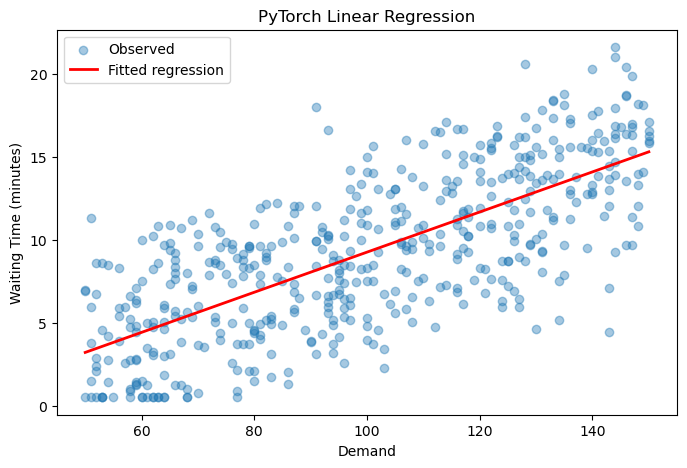

In [10]:
# Task 4 — Plot the regression line

x_line = np.linspace(
    df["demand"].min(),
    df["demand"].max(),
    100
)

x_line_df = pd.DataFrame({
    "demand": x_line
})

x_line_scaled = scaler.transform(x_line_df)

x_line_tensor = torch.tensor(
    x_line_scaled,
    dtype=torch.float32
)

with torch.no_grad():
    y_line = linear_model(
        x_line_tensor
    ).numpy().flatten()

plt.figure(figsize=(8, 5))

plt.scatter(
    df["demand"],
    df["wait_min"],
    alpha=0.4,
    label="Observed"
)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Fitted regression"
)

plt.xlabel("Demand")
plt.ylabel("Waiting Time (minutes)")
plt.title("PyTorch Linear Regression")
plt.legend()

plt.show()

In [11]:
# Task 5 — Make predictions and calculate residuals

new_data = pd.DataFrame({
    "demand": [120]
})

new_scaled = scaler.transform(new_data)

new_tensor = torch.tensor(
    new_scaled,
    dtype=torch.float32
)

with torch.no_grad():
    predicted_wait = linear_model(
        new_tensor
    ).item()

print("Predicted waiting time:", predicted_wait)

Predicted waiting time: 11.671409606933594


<Figure size 800x500 with 0 Axes>

Text(0.5, 0, 'Predicted Waiting Time')

Text(0, 0.5, 'Residual')

Text(0.5, 1.0, 'Linear Regression — Residual Plot')

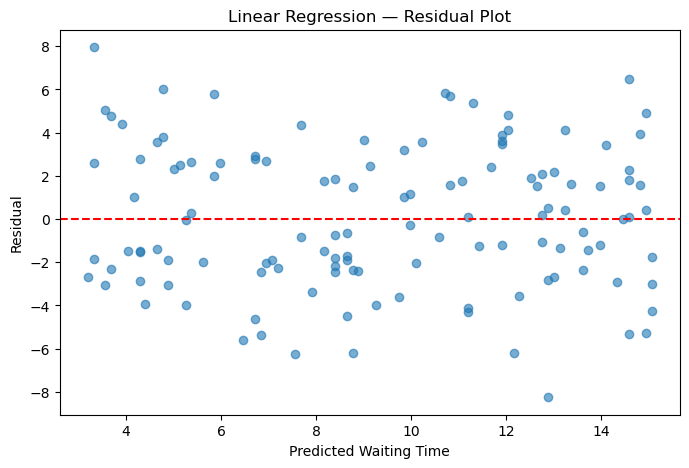

In [12]:
# Predict the test set:

with torch.no_grad():
    y_pred = linear_model(
        X_test_t
    ).numpy().flatten()

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Waiting Time")
plt.ylabel("Residual")
plt.title("Linear Regression — Residual Plot")

plt.show()

In [13]:
# Task 6 — Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  2.792
RMSE: 3.285
R²:   0.546


In [14]:
# Compare with a baseline

baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

print(f"Baseline MAE: {baseline_mae:.3f}")
print(f"PyTorch MAE:  {mae:.3f}")

Baseline MAE: 4.084
PyTorch MAE:  2.792


In [15]:
# Task 7 — Multiple Linear Regression


# Step A — Preprocess numerical and categorical features

features = [
    "demand",
    "supply",
    "distance_km",
    "peak",
    "weather"
]

X_multi = df[features]
y_multi = df["wait_min"]

X_train_m, X_test_m, y_train_m, y_test_m = (
    train_test_split(
        X_multi,
        y_multi,
        test_size=0.25,
        random_state=42
    )
)

preprocess_multi = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        ["demand", "supply", "distance_km"]
    ),
    (
        "cat",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ),
        ["peak", "weather"]
    )
])

X_train_processed = preprocess_multi.fit_transform(
    X_train_m
)

X_test_processed = preprocess_multi.transform(
    X_test_m
)

X_train_multi_t, y_train_multi_t = to_tensors(
    X_train_processed, y_train_m
)

X_test_multi_t, _ = to_tensors(
    X_test_processed, y_test_m
)

print("Number of input features:",
      X_train_multi_t.shape[1])

Number of input features: 5


In [16]:
# Step B — Train Multiple Linear Regression

torch.manual_seed(42)

multi_model = nn.Linear(
    in_features=X_train_multi_t.shape[1],
    out_features=1
)

multi_loss_fn = nn.MSELoss()

multi_history = train_torch_model(
    multi_model,
    X_train_multi_t,
    y_train_multi_t,
    multi_loss_fn,
    epochs=1200,
    lr=0.05
)

with torch.no_grad():
    y_pred_multi = multi_model(
        X_test_multi_t
    ).numpy().flatten()

print(
    "Multiple MAE:",
    mean_absolute_error(y_test_m, y_pred_multi)
)

print(
    "Multiple R²:",
    r2_score(y_test_m, y_pred_multi)
)

Multiple MAE: 1.5189889730072024
Multiple R²: 0.8400204711792473
